In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os
import time
from pathlib import Path
from collections import Counter

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [4]:
from pathlib import Path
import os

print("Lokasi kerja Python:")
print(os.getcwd())

print("\nIsi folder saat ini:")
print(os.listdir())

Lokasi kerja Python:
c:\Users\Admin\TUBES_IPSD_1-1\notebooks

Isi folder saat ini:
['simple_cnn.ipynb']


In [7]:
import os

print("Isi folder utama:")
print(os.listdir(".."))

Isi folder utama:
['.git', '.gitignore', '.venv', 'models', 'notebooks', 'README.md', 'requirements.txt', 'results']


In [10]:
# Lokasi dataset
BASE_DIR = Path(r"D:\TUBES_IPSD\archive(3)\dataset")

TRAIN_DIR = BASE_DIR / "train"
VALID_DIR = BASE_DIR / "valid"
TEST_DIR = BASE_DIR / "test"

print("Train:", TRAIN_DIR.exists())
print("Valid:", VALID_DIR.exists())
print("Test:", TEST_DIR.exists())

Train: True
Valid: True
Test: True


In [11]:
from torchvision import datasets

train_dataset = datasets.ImageFolder(TRAIN_DIR)
valid_dataset = datasets.ImageFolder(VALID_DIR)
test_dataset = datasets.ImageFolder(TEST_DIR)

print("Jumlah kelas:", len(train_dataset.classes))
print("Nama kelas:", train_dataset.classes)

print("Jumlah data training:", len(train_dataset))
print("Jumlah data validasi:", len(valid_dataset))
print("Jumlah data testing:", len(test_dataset))

Jumlah kelas: 50
Nama kelas: ['ARCIGERA FLOWER MOTH', 'ATLAS MOTH', 'BANDED TIGER MOTH', 'BIRD CHERRY ERMINE MOTH', 'BLACK RUSTIC MOTH', 'BLAIRS MOCHA', 'BLOTCHED EMERALD MOTH', 'BLUE BORDERED CARPET MOTH', 'CINNABAR MOTH', 'CLEARWING MOTH', 'COMET MOTH', 'DEATHS HEAD HAWK MOTH', 'ELEPHANT HAWK MOTH', 'EMPEROR GUM MOTH', 'EMPEROR MOTH', 'EYED HAWK MOTH', 'FIERY CLEARWING MOTH', 'GARDEN TIGER MOTH', 'HERCULES MOTH', 'HORNET MOTH', 'HUMMING BIRD HAWK MOTH', 'IO MOTH', 'JULY BELLE MOTH', 'KENTISH GLORY MOTH', 'LACE BORDER MOTH', 'LEOPARD MOTH', 'LUNA MOTH', 'MADAGASCAN SUNSET MOTH', 'MAGPIE MOTH', 'MUSLIN MOTH', 'OLEANDER HAWK MOTH', 'OWL MOTH', 'PALPITA VITREALIS MOTH', 'PEACH BLOSSOM MOTH', 'PLUME MOTH', 'POLYPHEMUS MOTH', 'PURPLE BORDERED GOLD MOTH', 'RED NECKED FOOTMAN MOTH', 'REGAL MOTH', 'ROSY MAPLE MOTH', 'ROSY UNDERWING MOTH', 'RUSTY DOT PEARL MOTH', 'SCHORCHED WING MOTH', 'SIXSPOT BURNET MOTH', 'SQUARE SPOT RUSTIC MOTH', 'SUSSEX EMERALD MOTH', 'SWALLOW TAILED MOTH', 'VESTAL MOTH'

In [12]:
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

#menghitung gambar setiap kelas
class_counts = Counter(train_dataset.targets)

#membuat tabel jumlah data
df_counts = pd.DataFrame({
    "Kelas": train_dataset.classes,
    "Jumlah Gambar": [
        class_counts[i] for i in range(len(train_dataset.classes))
    ]
})

display(df_counts)

print("Total kelas:", len(df_counts))
print("Total gambar:", df_counts["Jumlah Gambar"].sum())

,Kelas,Jumlah Gambar
0,ARCIGERA FLOWER MOTH,140
1,ATLAS MOTH,129
2,BANDED TIGER MOTH,136
3,BIRD CHERRY ERMINE MOTH,133
4,BLACK RUSTIC MOTH,134
5,BLAIRS MOCHA,177
6,BLOTCHED EMERALD MOTH,117
7,BLUE BORDERED CARPET MOTH,121
8,CINNABAR MOTH,131
9,CLEARWING MOTH,122


Total kelas: 50
Total gambar: 7183


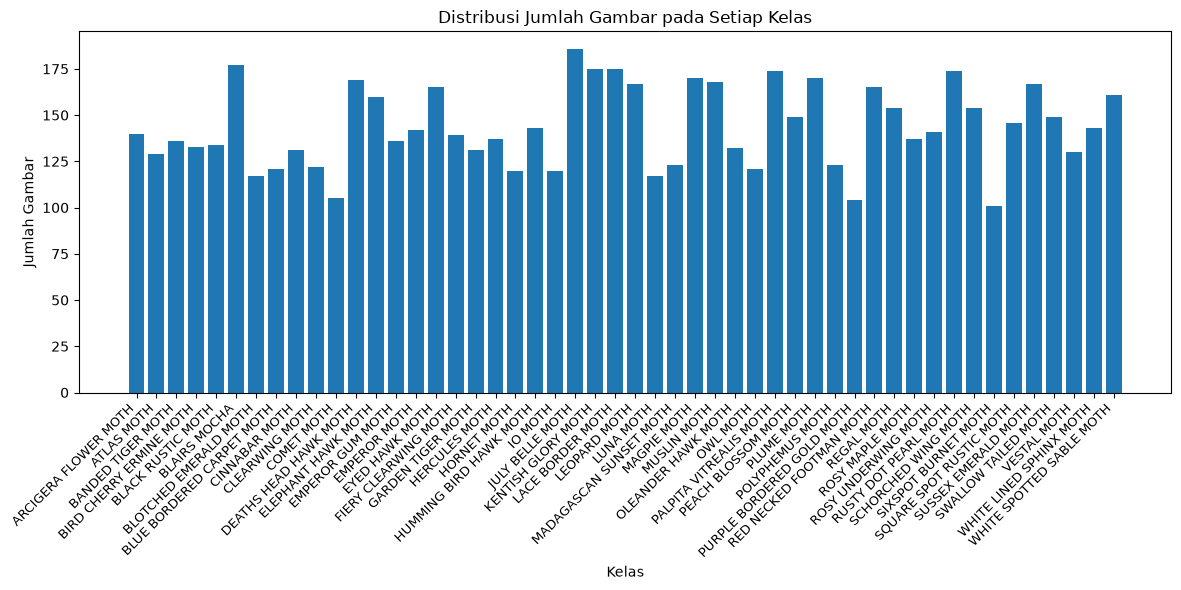

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    df_counts["Kelas"],
    df_counts["Jumlah Gambar"]
)

plt.title("Distribusi Jumlah Gambar pada Setiap Kelas")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Gambar")

plt.xticks(rotation=45, ha='right', fontsize=9)

plt.tight_layout()
plt.show()

In [15]:
from torchvision import transforms

# Preprocessing untuk data training
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Preprocessing untuk data validation
valid_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Preprocessing untuk data testing
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Preprocessing berhasil dibuat!")

Preprocessing berhasil dibuat!


In [16]:
from torchvision.datasets import ImageFolder

train_dataset = ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

valid_dataset = ImageFolder(
    root=VALID_DIR,
    transform=valid_transform
)

test_dataset = ImageFolder(
    root=TEST_DIR,
    transform=test_transform
)

print("Jumlah data training:", len(train_dataset))
print("Jumlah data validation:", len(valid_dataset))
print("Jumlah data testing:", len(test_dataset))

print("Daftar kelas:", train_dataset.classes)

Jumlah data training: 7183
Jumlah data validation: 250
Jumlah data testing: 250
Daftar kelas: ['ARCIGERA FLOWER MOTH', 'ATLAS MOTH', 'BANDED TIGER MOTH', 'BIRD CHERRY ERMINE MOTH', 'BLACK RUSTIC MOTH', 'BLAIRS MOCHA', 'BLOTCHED EMERALD MOTH', 'BLUE BORDERED CARPET MOTH', 'CINNABAR MOTH', 'CLEARWING MOTH', 'COMET MOTH', 'DEATHS HEAD HAWK MOTH', 'ELEPHANT HAWK MOTH', 'EMPEROR GUM MOTH', 'EMPEROR MOTH', 'EYED HAWK MOTH', 'FIERY CLEARWING MOTH', 'GARDEN TIGER MOTH', 'HERCULES MOTH', 'HORNET MOTH', 'HUMMING BIRD HAWK MOTH', 'IO MOTH', 'JULY BELLE MOTH', 'KENTISH GLORY MOTH', 'LACE BORDER MOTH', 'LEOPARD MOTH', 'LUNA MOTH', 'MADAGASCAN SUNSET MOTH', 'MAGPIE MOTH', 'MUSLIN MOTH', 'OLEANDER HAWK MOTH', 'OWL MOTH', 'PALPITA VITREALIS MOTH', 'PEACH BLOSSOM MOTH', 'PLUME MOTH', 'POLYPHEMUS MOTH', 'PURPLE BORDERED GOLD MOTH', 'RED NECKED FOOTMAN MOTH', 'REGAL MOTH', 'ROSY MAPLE MOTH', 'ROSY UNDERWING MOTH', 'RUSTY DOT PEARL MOTH', 'SCHORCHED WING MOTH', 'SIXSPOT BURNET MOTH', 'SQUARE SPOT RUSTIC M

In [17]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoader berhasil dibuat!")

DataLoader berhasil dibuat!


In [18]:
images, labels = next(iter(train_loader))

print("Ukuran batch gambar:", images.shape)
print("Ukuran batch label:", labels.shape)
print("Nama kelas:", train_dataset.classes)

Ukuran batch gambar: torch.Size([32, 3, 224, 224])
Ukuran batch label: torch.Size([32])
Nama kelas: ['ARCIGERA FLOWER MOTH', 'ATLAS MOTH', 'BANDED TIGER MOTH', 'BIRD CHERRY ERMINE MOTH', 'BLACK RUSTIC MOTH', 'BLAIRS MOCHA', 'BLOTCHED EMERALD MOTH', 'BLUE BORDERED CARPET MOTH', 'CINNABAR MOTH', 'CLEARWING MOTH', 'COMET MOTH', 'DEATHS HEAD HAWK MOTH', 'ELEPHANT HAWK MOTH', 'EMPEROR GUM MOTH', 'EMPEROR MOTH', 'EYED HAWK MOTH', 'FIERY CLEARWING MOTH', 'GARDEN TIGER MOTH', 'HERCULES MOTH', 'HORNET MOTH', 'HUMMING BIRD HAWK MOTH', 'IO MOTH', 'JULY BELLE MOTH', 'KENTISH GLORY MOTH', 'LACE BORDER MOTH', 'LEOPARD MOTH', 'LUNA MOTH', 'MADAGASCAN SUNSET MOTH', 'MAGPIE MOTH', 'MUSLIN MOTH', 'OLEANDER HAWK MOTH', 'OWL MOTH', 'PALPITA VITREALIS MOTH', 'PEACH BLOSSOM MOTH', 'PLUME MOTH', 'POLYPHEMUS MOTH', 'PURPLE BORDERED GOLD MOTH', 'RED NECKED FOOTMAN MOTH', 'REGAL MOTH', 'ROSY MAPLE MOTH', 'ROSY UNDERWING MOTH', 'RUSTY DOT PEARL MOTH', 'SCHORCHED WING MOTH', 'SIXSPOT BURNET MOTH', 'SQUARE SPOT RU

In [19]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device yang digunakan:", device)

Device yang digunakan: cpu


In [20]:
class SimpleCNN(nn.Module):

    def __init__(self, num_classes):
        super(SimpleCNN, self).__init__()

        self.features = nn.Sequential(

            # Convolution Layer 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Convolution Layer 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Convolution Layer 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 28 * 28, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [21]:
num_classes = len(train_dataset.classes)

model = SimpleCNN(num_classes=num_classes).to(device)

print(model)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=100352, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=50, bias=True)
  )
)


In [22]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function dan optimizer berhasil dibuat!")

Loss function dan optimizer berhasil dibuat!


In [23]:
images, labels = next(iter(train_loader))

images = images.to(device)

model.eval()

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 50])


In [24]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Menghapus gradient sebelumnya
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Menghitung loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Memperbarui bobot
        optimizer.step()

        running_loss += loss.item()

        # Menghitung prediksi
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [25]:
def validate(model, valid_loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in valid_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(valid_loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [27]:
num_epochs = 5

train_losses = []
train_accuracies = []

valid_losses = []
valid_accuracies = []

for epoch in range(num_epochs):

    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    valid_loss, valid_acc = validate(
        model, valid_loader, criterion, device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    valid_losses.append(valid_loss)
    valid_accuracies.append(valid_acc)

    print(f"Epoch [{epoch+1}/{num_epochs}]")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
    print(f"Valid Loss: {valid_loss:.4f} | Valid Accuracy: {valid_acc:.2f}%")
    print("-" * 50)

Epoch [1/5]
Train Loss: 3.4387 | Train Accuracy: 10.18%
Valid Loss: 2.5895 | Valid Accuracy: 29.60%
--------------------------------------------------
Epoch [2/5]
Train Loss: 2.5495 | Train Accuracy: 27.83%
Valid Loss: 1.6730 | Valid Accuracy: 50.40%
--------------------------------------------------
Epoch [3/5]
Train Loss: 2.0788 | Train Accuracy: 39.80%
Valid Loss: 1.4496 | Valid Accuracy: 53.60%
--------------------------------------------------
Epoch [4/5]
Train Loss: 1.8032 | Train Accuracy: 47.81%
Valid Loss: 1.1313 | Valid Accuracy: 67.60%
--------------------------------------------------
Epoch [5/5]
Train Loss: 1.5812 | Train Accuracy: 54.13%
Valid Loss: 1.0032 | Valid Accuracy: 70.80%
--------------------------------------------------


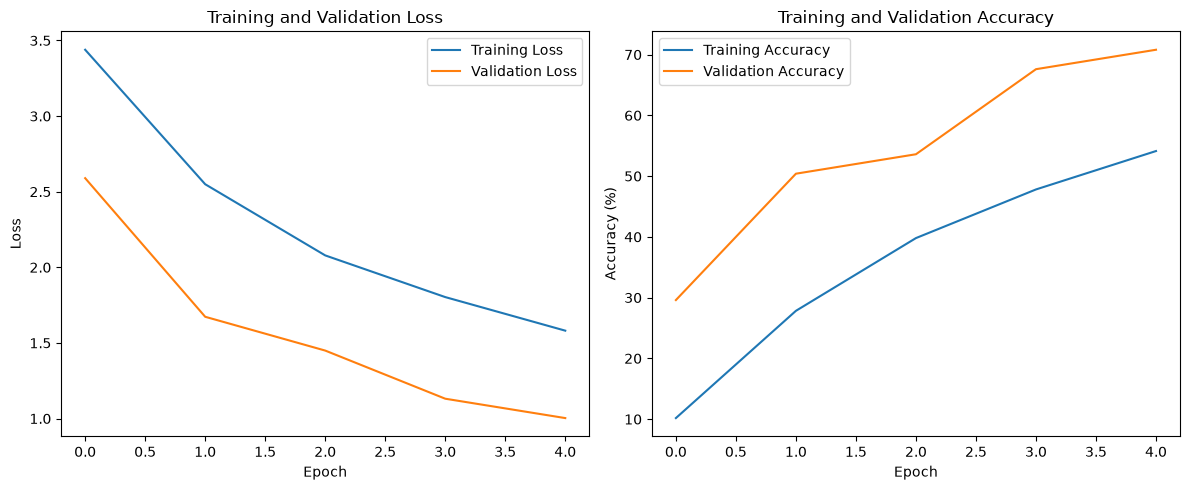

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Grafik Loss
plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Training Loss")
plt.plot(valid_losses, label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

# Grafik Accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(valid_accuracies, label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()

plt.tight_layout()
plt.show()

In [29]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_preds,
    target_names=test_dataset.classes
))

                           precision    recall  f1-score   support

     ARCIGERA FLOWER MOTH       0.50      0.60      0.55         5
               ATLAS MOTH       1.00      0.60      0.75         5
        BANDED TIGER MOTH       0.50      0.60      0.55         5
  BIRD CHERRY ERMINE MOTH       0.67      0.80      0.73         5
        BLACK RUSTIC MOTH       0.43      0.60      0.50         5
             BLAIRS MOCHA       0.83      1.00      0.91         5
    BLOTCHED EMERALD MOTH       0.00      0.00      0.00         5
BLUE BORDERED CARPET MOTH       1.00      0.60      0.75         5
            CINNABAR MOTH       0.83      1.00      0.91         5
           CLEARWING MOTH       0.80      0.80      0.80         5
               COMET MOTH       1.00      1.00      1.00         5
    DEATHS HEAD HAWK MOTH       0.71      1.00      0.83         5
       ELEPHANT HAWK MOTH       0.50      0.40      0.44         5
         EMPEROR GUM MOTH       1.00      0.60      0.75     

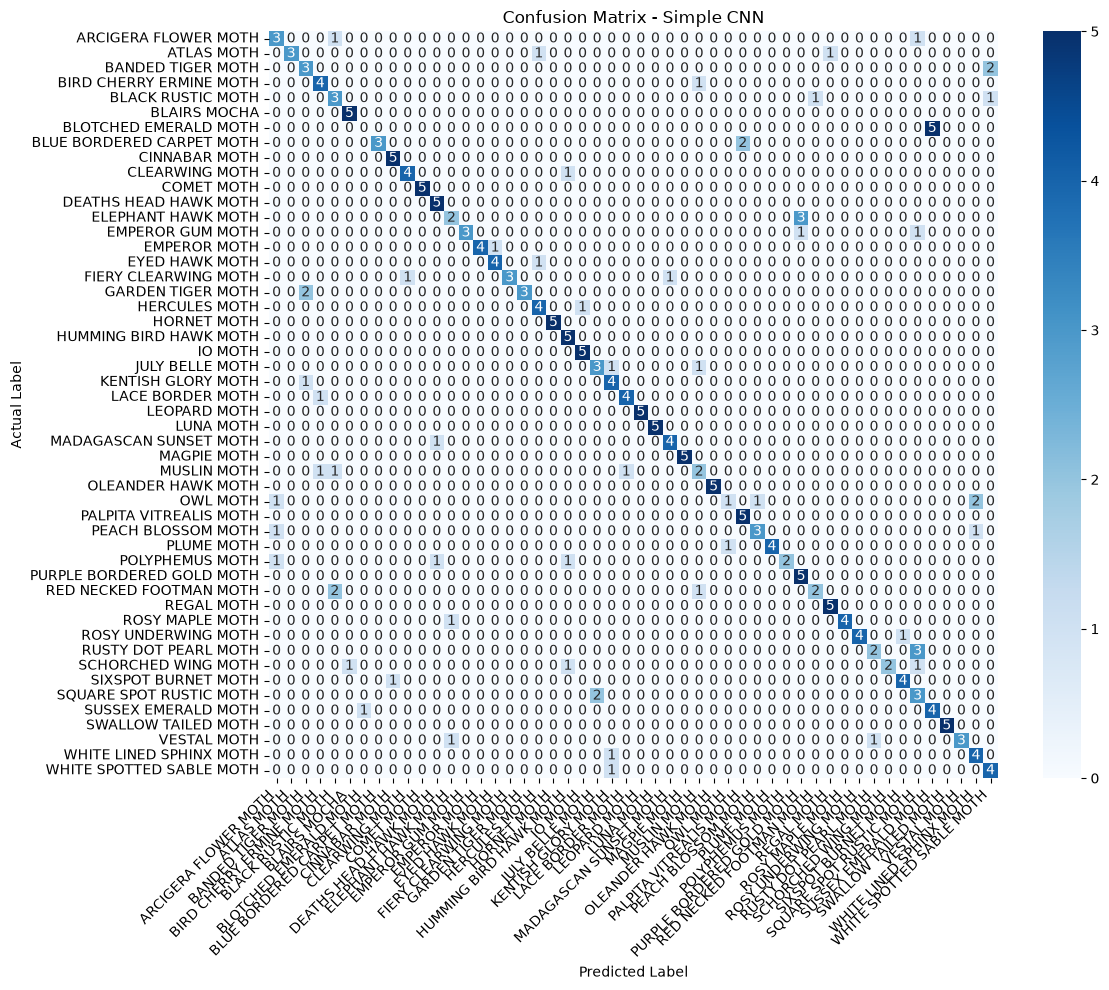

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes
)

plt.title("Confusion Matrix - Simple CNN")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()